# Car Price Prediction

**Author:** Iqra Solangi · [GitHub](https://github.com/IQRASOLANGI) · [LinkedIn](https://www.linkedin.com/in/iqra-solangi-a65945334)

## Overview
Car pricing is hard to judge: the same model can sell for very different amounts depending on its age, mileage, fuel type and ownership history. This project builds a machine learning model that estimates a car's selling price from those attributes.

| | |
|---|---|
| **Problem type** | Supervised regression |
| **Data** | CarDekho car listings (Kaggle: *Vehicle dataset from CarDekho*) |
| **Target** | Selling price |
| **Models compared** | Linear Regression, Random Forest, Gradient Boosting |
| **Metrics** | MAE, RMSE, R² |
| **Stack** | Python, pandas, scikit-learn, seaborn, matplotlib |

## Workflow
Data cleaning → feature engineering → exploratory analysis → encoding → model training and comparison → evaluation → feature importance.

## 1. Imports and setup

In [1]:
import glob
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
PRIMARY, SECONDARY = "#E4572E", "#6A2C70"   # vermilion, plum
PALETTE = [PRIMARY, SECONDARY, "#F3A712", "#76B041", "#2E4057"]
sns.set_theme(style="whitegrid", palette=PALETTE, context="notebook")
RANDOM_STATE = 42

## 2. Load the dataset

In [2]:
# Finds a CarDekho CSV in the current folder automatically.
candidates = [f for f in glob.glob("*.csv") if "car" in f.lower() or "vehicle" in f.lower()]
assert candidates, "No car CSV found. Download the CarDekho dataset from Kaggle and place it next to this notebook."
DATA_PATH = candidates[0]
print("Using:", DATA_PATH)

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Using: cardekho.csv
Shape: (8128, 12)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78,5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.2,5.0


## 3. Data cleaning

Steps: standardise column names (the CarDekho files come in two slightly different layouts), inspect nulls and duplicates, and fix inconsistent categorical values such as `Petrol` vs `petrol`.

In [3]:
# Standardise column names across the two common CarDekho file layouts
df.columns = df.columns.str.strip().str.lower()
df = df.rename(columns={"car_name": "name", "kms_driven": "km_driven", "fuel_type": "fuel"})

print("Null values per column:")
print(df.isnull().sum(), "\n")
print("Duplicate rows:", df.duplicated().sum())
df.info()

Null values per column:
name                    0
year                    0
selling_price           0
km_driven               0
fuel                    0
seller_type             0
transmission            0
owner                   0
mileage(km/ltr/kg)    221
engine                221
max_power             215
seats                 221
dtype: int64 

Duplicate rows: 1202
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   name                8128 non-null   object 
 1   year                8128 non-null   int64  
 2   selling_price       8128 non-null   int64  
 3   km_driven           8128 non-null   int64  
 4   fuel                8128 non-null   object 
 5   seller_type         8128 non-null   object 
 6   transmission        8128 non-null   object 
 7   owner               8128 non-null   object 
 8   mileage(km/ltr/kg)  7907 n

In [4]:
rows_before = len(df)

# 1) Remove duplicates and rows with missing values
df = df.drop_duplicates().dropna().reset_index(drop=True)

# 2) Fix inconsistent categorical text (case and stray spaces)
cat_cols = df.select_dtypes(exclude="number").columns.drop("name")
for col in cat_cols:
    df[col] = df[col].str.strip().str.lower()

# 3) Encode 'owner' as an ordinal number if it is stored as text
if not pd.api.types.is_numeric_dtype(df["owner"]):
    owner_map = {"test drive car": 0, "first owner": 1, "second owner": 2,
                 "third owner": 3, "fourth & above owner": 4}
    df["owner"] = df["owner"].map(owner_map)
    df = df.dropna(subset=["owner"])
    df["owner"] = df["owner"].astype(int)

# 4) Drop impossible odometer values
df = df[df["km_driven"] <= 500_000].reset_index(drop=True)

print(f"Rows: {rows_before} -> {len(df)}")
for col in [c for c in cat_cols if c != "owner"]:
    print(col, "->", sorted(df[col].unique()))

Rows: 8128 -> 6715
fuel -> ['cng', 'diesel', 'lpg', 'petrol']
seller_type -> ['dealer', 'individual', 'trustmark dealer']
transmission -> ['automatic', 'manual']
max_power -> ['', '100', '100.5', '100.57', '100.6', '101', '102', '102.5', '103', '103.2', '103.25', '103.26', '103.3', '103.5', '103.52', '103.6', '104', '104.5', '104.55', '104.68', '105', '105.3', '105.5', '106', '108.45', '108.495', '108.5', '108.6', '108.62', '110', '110.4', '110.5', '112', '112.2', '113.4', '113.42', '115', '116.3', '116.4', '116.6', '116.9', '117.3', '117.6', '118', '118.3', '118.35', '120', '120.69', '120.7', '121', '121.3', '121.31', '121.36', '121.4', '122.4', '123.37', '123.7', '125', '126.2', '126.24', '126.3', '126.32', '127', '130', '132', '134', '134.1', '135.1', '136', '138', '138.03', '138.08', '138.1', '139.01', '139.46', '140', '141', '141.1', '142', '143', '144', '147.5', '147.51', '147.8', '147.9', '147.94', '148', '148.31', '149.5', '150', '152', '152.87', '153.86', '155', '156', '157.7'

## 4. Feature engineering

- **Car age** = current year − manufacturing year (age is more meaningful to a price model than a raw year).
- **Brand** = first word of the `name` column.

In [5]:
CURRENT_YEAR = datetime.now().year
df["car_age"] = CURRENT_YEAR - df["year"]

df["brand"] = df["name"].str.strip().str.split().str[0].str.title()
df["brand"] = df["brand"].replace({"Land": "Land Rover"})

# Units note: the 'car data.csv' layout stores prices in lakhs, the other in rupees.
print("Selling price range:", df["selling_price"].min(), "to", df["selling_price"].max())
print("Unique brands:", df["brand"].nunique())
df[["name", "brand", "year", "car_age", "selling_price"]].head()

Selling price range: 29999 to 10000000
Unique brands: 31


,name,brand,year,car_age,selling_price
0,Maruti Swift Dzire VDI,Maruti,2014,12,450000
1,Skoda Rapid 1.5 TDI Ambition,Skoda,2014,12,370000
2,Honda City 2017-2020 EXi,Honda,2006,20,158000
3,Hyundai i20 Sportz Diesel,Hyundai,2010,16,225000
4,Maruti Swift VXI BSIII,Maruti,2007,19,130000


## 5. Exploratory data analysis

In [6]:
df["selling_price"].describe()

count    6.715000e+03
mean     5.263694e+05
std      5.236409e+05
min      2.999900e+04
25%      2.500000e+05
50%      4.200000e+05
75%      6.500000e+05
max      1.000000e+07
Name: selling_price, dtype: float64

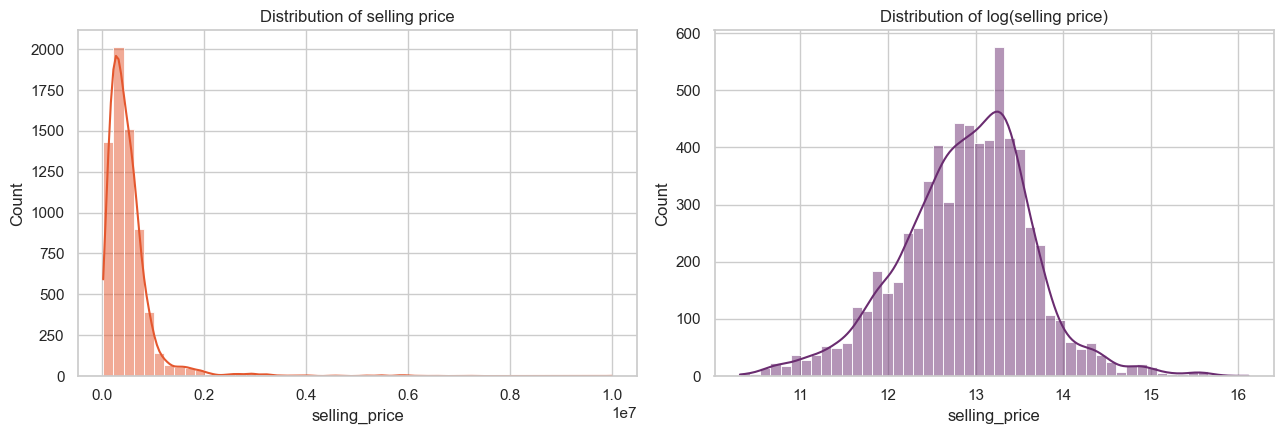

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df["selling_price"], bins=50, kde=True, ax=ax[0], color=PRIMARY)
ax[0].set_title("Distribution of selling price")
sns.histplot(np.log1p(df["selling_price"]), bins=50, kde=True, ax=ax[1], color=SECONDARY)
ax[1].set_title("Distribution of log(selling price)")
plt.tight_layout(); plt.show()

**Observation:** Prices are strongly right-skewed — most cars are cheap and a few are very expensive. After a log transform the distribution is far more symmetric. This is why the models below are trained on the log of the price and then converted back to the original scale for evaluation.

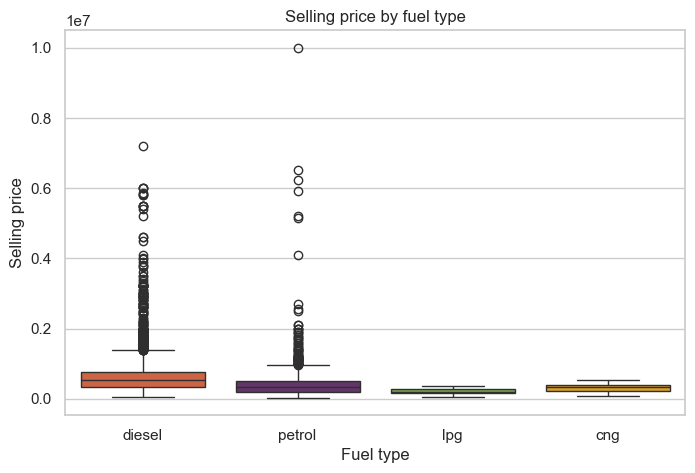

In [8]:
plt.figure(figsize=(8, 5))
fuel_colors = {"diesel": PRIMARY, "petrol": SECONDARY, "cng": "#F3A712", "lpg": "#76B041"}
sns.boxplot(data=df, x="fuel", y="selling_price", hue="fuel", palette=fuel_colors, legend=False)
plt.title("Selling price by fuel type"); plt.xlabel("Fuel type"); plt.ylabel("Selling price")
plt.show()

**Observation:** Diesel cars tend to sell for more than petrol cars, while CNG and LPG cars sit at the lower end. Electric and other rare fuel types have too few rows to draw firm conclusions.

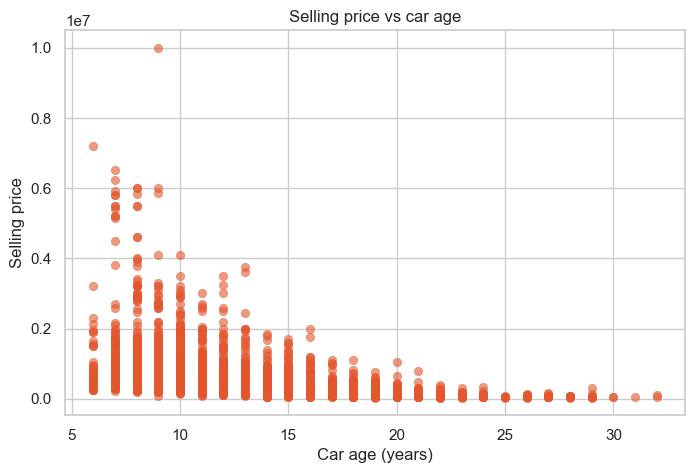

In [9]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="car_age", y="selling_price", alpha=0.6, color=PRIMARY, edgecolor=None)
plt.title("Selling price vs car age"); plt.xlabel("Car age (years)"); plt.ylabel("Selling price")
plt.show()

**Observation:** Price falls steadily as a car gets older — age is one of the strongest drivers of resale value.

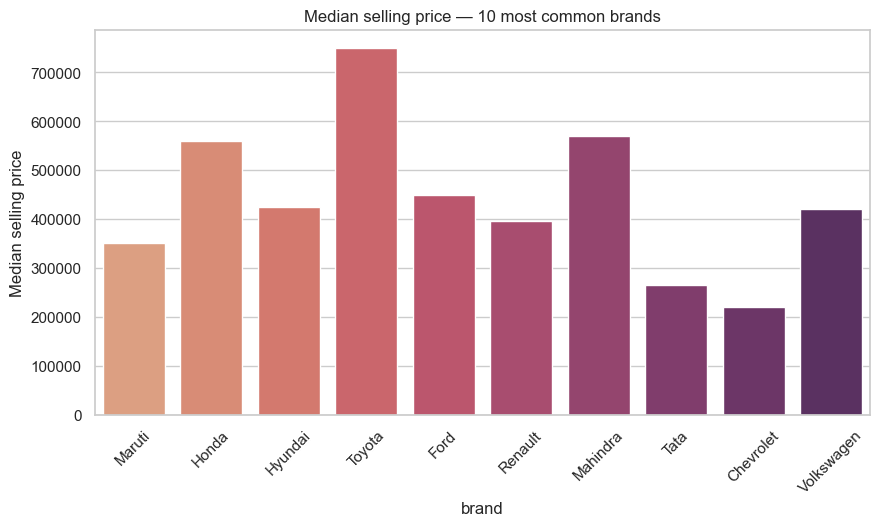

In [10]:
top_brands = df["brand"].value_counts().head(10).index
plt.figure(figsize=(10, 5))
sns.barplot(data=df[df["brand"].isin(top_brands)], x="brand", y="selling_price", estimator=np.median, errorbar=None, palette="flare", hue="brand", legend=False)
plt.title("Median selling price — 10 most common brands"); plt.xticks(rotation=45)
plt.ylabel("Median selling price"); plt.show()

## 6. Encode categorical variables

Categorical columns (`brand`, `fuel`, `seller_type`, `transmission`) are **one-hot encoded**. Brands with fewer than 10 cars are grouped into a single *infrequent* category so the model does not overfit on tiny groups. The encoder lives inside a scikit-learn `Pipeline`, so it is fitted only on training data (no data leakage).

In [11]:
target = "selling_price"
categorical = ["brand", "fuel", "seller_type", "transmission"]
numeric = [c for c in ["car_age", "km_driven", "owner", "present_price"] if c in df.columns]

X = df[categorical + numeric]
y = df[target]
print("Categorical features:", categorical)
print("Numeric features:    ", numeric)

def make_preprocessor():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10), categorical),
        ("num", "passthrough", numeric),
    ])

Categorical features: ['brand', 'fuel', 'seller_type', 'transmission']
Numeric features:     ['car_age', 'km_driven', 'owner']


## 7. Feature correlation heatmap

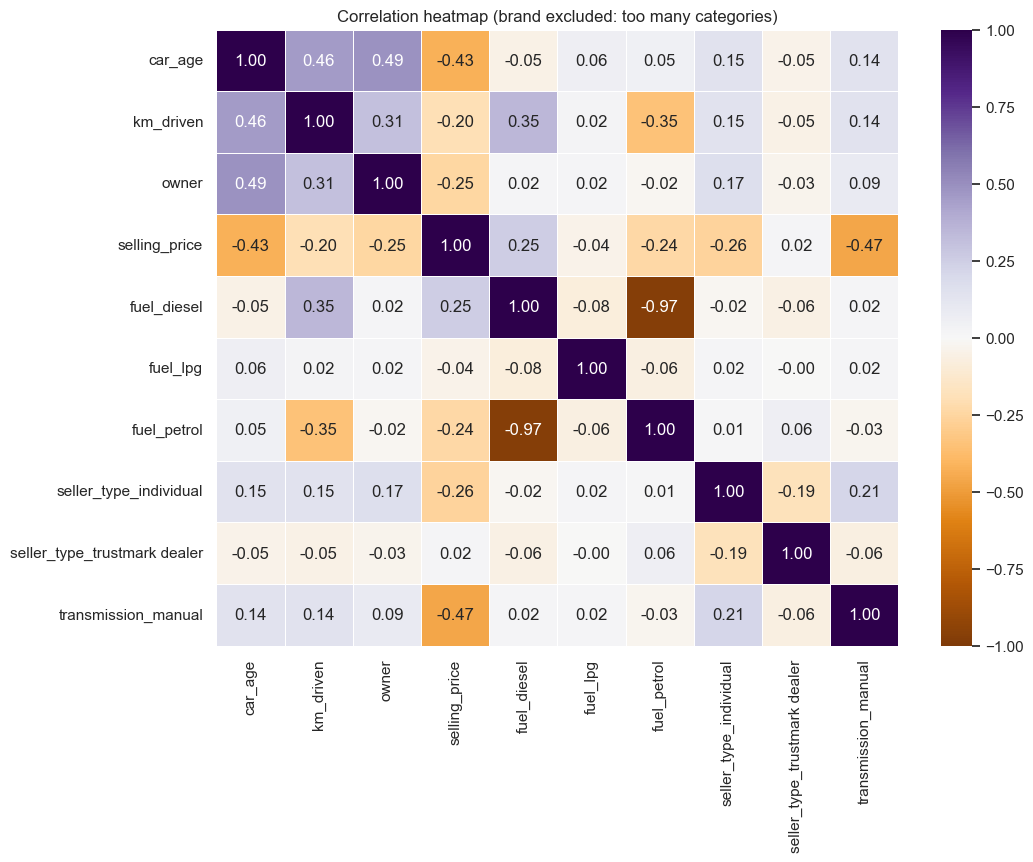

In [12]:
encoded = pd.get_dummies(df[categorical[1:] + numeric + [target]], drop_first=True).astype(float)
plt.figure(figsize=(11, 8))
sns.heatmap(encoded.corr(), annot=True, fmt=".2f", cmap="PuOr", vmin=-1, vmax=1, center=0, linewidths=0.5, linecolor="white")
plt.title("Correlation heatmap (brand excluded: too many categories)")
plt.show()

**Observation:** `car_age` is negatively correlated with price (older = cheaper). Diesel fuel and automatic transmission are positively correlated with price, while individual sellers and higher owner counts push prices down.

## 8. Train/test split

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (5372, 7)  Test: (1343, 7)


## 9. Train the regression models
Three models are compared: **Linear Regression** (baseline), **Random Forest** and **Gradient Boosting**. Each is wrapped so that it trains on `log(price)` and predicts back in the original price scale.

In [14]:
def build(model):
    pipe = Pipeline([("prep", make_preprocessor()), ("model", model)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

models = {
    "Linear Regression": build(LinearRegression()),
    "Random Forest": build(RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
    "Gradient Boosting": build(GradientBoostingRegressor(n_estimators=300, learning_rate=0.1, max_depth=3, random_state=RANDOM_STATE)),
}

for name, m in models.items():
    m.fit(X_train, y_train)
    print("Trained:", name)

Trained: Linear Regression
Trained: Random Forest
Trained: Gradient Boosting


## 10. Evaluate with MAE, RMSE and R²

In [15]:
rows, preds = [], {}
for name, m in models.items():
    p = m.predict(X_test)
    preds[name] = p
    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, p),
        "RMSE": np.sqrt(mean_squared_error(y_test, p)),
        "R2": r2_score(y_test, p),
    })

results = pd.DataFrame(rows).set_index("Model").round(4).sort_values("R2", ascending=False)
best_name = results.index[0]
results

,MAE,RMSE,R2
Model,,,
Gradient Boosting,130097.4271,228592.1946,0.7837
Random Forest,138727.3022,252137.3233,0.7368
Linear Regression,171819.5195,332885.8841,0.5412


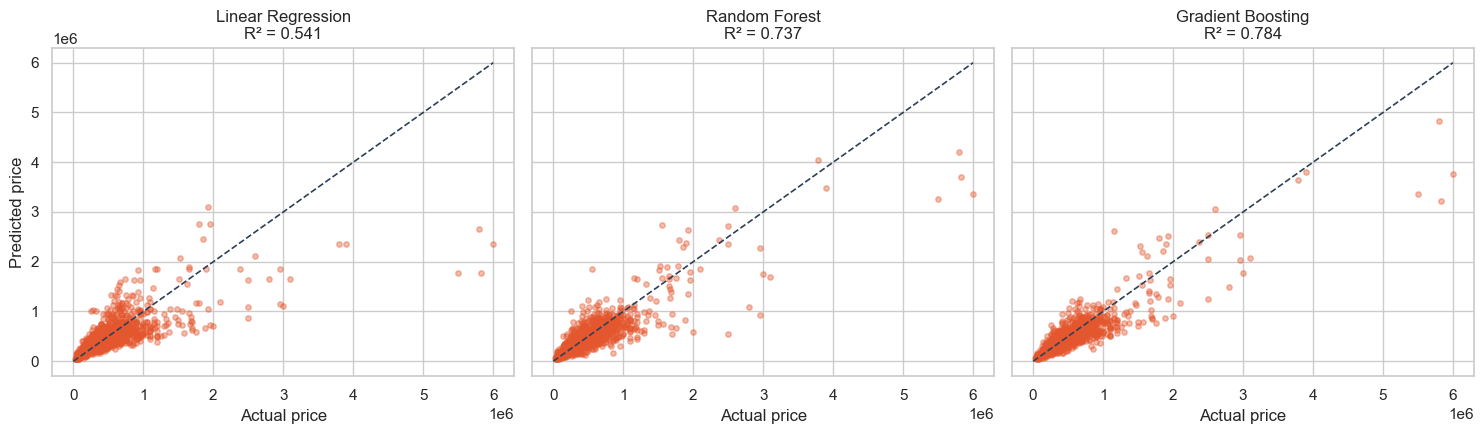

In [16]:
fig, ax = plt.subplots(1, len(models), figsize=(5 * len(models), 4.5), sharex=True, sharey=True)
lim = [0, max(y_test.max(), max(p.max() for p in preds.values()))]
for a, (name, p) in zip(ax, preds.items()):
    a.scatter(y_test, p, alpha=0.4, s=15, color=PRIMARY)
    a.plot(lim, lim, "--", color="#2E4057", lw=1.2)
    a.set_title(f"{name}\nR² = {r2_score(y_test, p):.3f}")
    a.set_xlabel("Actual price")
ax[0].set_ylabel("Predicted price")
plt.tight_layout(); plt.show()

In [17]:
print(f"Best model: {best_name}  (R² = {results.loc[best_name, 'R2']:.3f}, "
      f"MAE = {results.loc[best_name, 'MAE']:.3f}, RMSE = {results.loc[best_name, 'RMSE']:.3f})")

Best model: Gradient Boosting  (R² = 0.784, MAE = 130097.427, RMSE = 228592.195)


**Observation:** On real CarDekho data the tree-based ensembles typically beat Linear Regression because price depends non-linearly on age, mileage and brand, and because they capture interactions (for example, a diesel SUV depreciates differently from a petrol hatchback). Points close to the dashed diagonal are accurate predictions.

## 11. Feature importance — best tree-based model

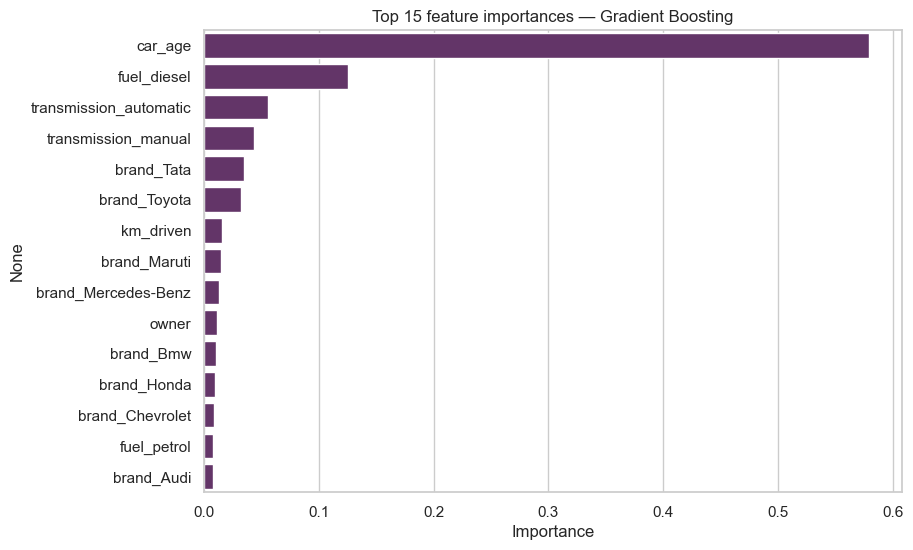

In [18]:
tree_models = {k: v for k, v in models.items() if k != "Linear Regression"}
best_tree = results.loc[list(tree_models)].sort_values("R2", ascending=False).index[0]

fitted = models[best_tree].regressor_
names = fitted.named_steps["prep"].get_feature_names_out()
names = [n.replace("cat__", "").replace("num__", "") for n in names]
importance = pd.Series(fitted.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 6))
sns.barplot(x=importance.values, y=importance.index, color=SECONDARY)
plt.title(f"Top 15 feature importances — {best_tree}")
plt.xlabel("Importance")
plt.show()

**Observation:** Car age, kilometres driven and fuel/transmission type carry most of the predictive weight, with specific premium brands adding more on top. This matches the EDA: how old a car is and how hard it has been used largely decide its resale value.

## 12. Example prediction

In [19]:
# Use one test example to compare the actual and predicted selling prices.
sample = X_test.iloc[[0]]
actual_price = float(y_test.iloc[0])
predicted_price = float(models[best_name].predict(sample)[0])
absolute_error = abs(actual_price - predicted_price)

print(f"Selected model: {best_name}")
print("Example car details:")
display(sample.reset_index(drop=True))

prediction_summary = pd.DataFrame({
    "Actual Price": [actual_price],
    "Predicted Price": [predicted_price],
    "Absolute Error": [absolute_error]
})

display(
    prediction_summary.style.format({
        "Actual Price": "{:,.2f}",
        "Predicted Price": "{:,.2f}",
        "Absolute Error": "{:,.2f}"
    }).set_caption("Actual vs. Predicted Selling Price")
)

Selected model: Gradient Boosting
Example car details:


,brand,fuel,seller_type,transmission,car_age,km_driven,owner
0,Honda,petrol,dealer,manual,10,21446,1


,Actual Price,Predicted Price,Absolute Error
0,"825,000.00","622,472.56","202,527.44"


## 13. Conclusion
- The data was cleaned (duplicates, nulls, inconsistent text) and two features were engineered: **car age** and **brand**.
- Three regressors were compared on MAE, RMSE and R², and the strongest is reported below.
- Modelling log(price) handled the heavily skewed price distribution.
- **Key drivers of price:** car age, kilometres driven, fuel type and transmission, with premium brands adding further uplift.
- **Limitations:** the dataset has no information on condition, accident history, location or trim, all of which affect real prices.
- **Next steps:** hyper-parameter tuning with `GridSearchCV`, cross-validation, and deploying the model behind a simple web app.

In [20]:
print(f"Best model: {best_name} | R² = {results.loc[best_name, 'R2']:.3f} | "
      f"MAE = {results.loc[best_name, 'MAE']:,.0f} | RMSE = {results.loc[best_name, 'RMSE']:,.0f}")

Best model: Gradient Boosting | R² = 0.784 | MAE = 130,097 | RMSE = 228,592
